# Projeto 01: agente de recolha e entrega de alimentos locais

Fundamentos de Inteligência Artificial, 2026-27. Grupo G09.

| Nome | Número |
|---|---|
| Gonçalo Tierri | 23020 |
| Ricardo Oliveira | 20432 |

## 1. Introdução

Uma plataforma liga pequenos produtores do distrito de Braga aos clientes através de um centro de recolha com dois veículos. Cada produto é recolhido no produtor, passa pelo armazém e é entregue ao cliente. Queremos servir todas as encomendas com o menor número de km, respeitando janelas temporais, capacidades, tempos de serviço e um máximo de 24 h no armazém.

Usamos três técnicas: pesquisa informada com Greedy e A\*, pesquisa local com Hill Climbing e Simulated Annealing, e CSP. Os notebooks 02 a 05 detalham cada parte; o código está em `src/`.

In [2]:
# imports e carregamento dos dois datasets
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.model import (load_problem, read_tables, audit, evaluate, check_solution, schedule_table, State,
                       plot_locations, plot_routes, plot_gantt, plot_histories)
from src.informed import greedy, astar, astar_trips, weighted_astar, catalog, HEURISTICS, h_mst, h_relaxed
from src.local_search import hill_climbing, simulated_annealing
from src.csp import solve, RoutingCSP

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
tiny = load_problem(ROOT / "data_tiny")
small = load_problem(ROOT / "data_small")
PROBLEMS = {"tiny": tiny, "small": small}


def print_routes(solution):
    for vehicle, trips in solution.items():
        print(f"Veículo {vehicle}:", " | ".join("W→" + "→".join(trip) + "→W" for trip in trips))

## 2. Análise exploratória

Resumo do notebook 02.

In [3]:
# dimensão de cada dataset, com a procura face à capacidade da frota
tables = {name: read_tables(ROOT / f"data_{name}") for name in ("tiny", "small")}
pd.DataFrame({name: dict(
    encomendas=len(data["orders"]), linhas=len(data["order_items"]), produtores=len(data["producers"]),
    locais_entrega=len(data["delivery_locations"]), veiculos=len(data["vehicles"]),
    capacidade_kg=" + ".join(f"{c:.0f}" for c in data["vehicles"].capacity_kg),
    procura_kg=round(data["order_items"].weight_kg.sum(), 1)) for name, data in tables.items()})

,tiny,small
encomendas,12,25
linhas,40,80
produtores,3,6
locais_entrega,5,7
veiculos,2,2
capacidade_kg,150 + 200,250 + 300
procura_kg,270.0,580.0


In [4]:
# auditoria de integridade, resumida por estado
audit_results = pd.concat([audit(data).assign(dataset=name) for name, data in tables.items()])
audit_results.pivot_table(index="status", columns="dataset", values="check", aggfunc="count", fill_value=0)

dataset,small,tiny
status,,
info,2,2
ok,67,67


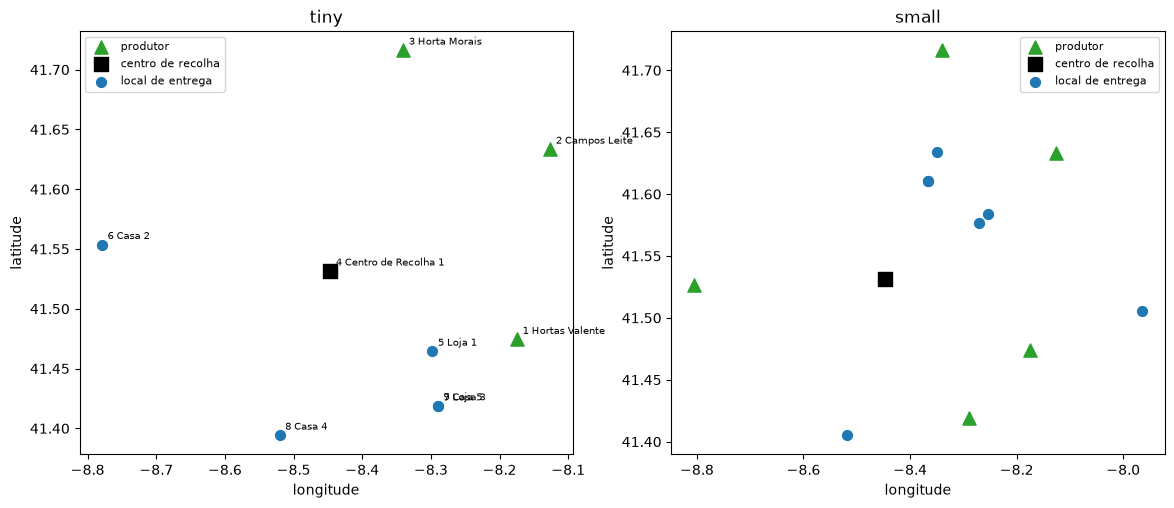

In [5]:
# mapa das paragens
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_locations(tiny, axes[0])
axes[0].set_title("tiny")
plot_locations(small, axes[1], labels=False)
axes[1].set_title("small");

Os dados estão limpos: a auditoria não encontra erros em nenhum dos datasets. As restrições que mais apertam são as temporais. No tiny, três encomendas passam a noite no armazém, com 25 a 29 h entre a recolha e a entrega, por isso o limite de 24 h conta. Todos os locais ficam a 19–38 km do centro, por isso o número de viagens domina o custo. No small, os 580 kg de procura já passam os 550 kg de capacidade da frota.

## 3. Modelação

Contamos o tempo em minutos desde o início do horizonte. Uma recolha junta as linhas do mesmo produtor com janelas que se intersetam, e uma entrega é uma encomenda. No tiny, as 40 linhas dão 6 recolhas.

Cada veículo faz viagens que saem do centro e voltam lá. Uma viagem só tem recolhas ou só entregas e não passa a meia-noite, e os veículos saem a tempo de chegar à primeira paragem quando a janela abre. Um veículo pode entregar o que outro recolheu, depois de descarregado no armazém. O objetivo é minimizar os km. Ignoramos a refrigeração, porque os dados não dizem que produtos precisam de frio.

Em `src/model.py`, `Problem` guarda os pedidos, a frota, as distâncias e as regras; `Request` é uma recolha ou entrega, `Vehicle` um veículo e `State` um nó da pesquisa informada. `evaluate(problem, solution)` simula uma solução `{veículo: [viagens]}` e devolve os km e as violações. A pesquisa local usa um custo penalizado: `km + 100·(atraso + excesso de carga + excesso de permanência) + 10 000·(erros estruturais)`.

In [6]:
# os 18 pedidos do tiny depois do agrupamento
rows = [dict(id=request_id, tipo=request.kind, local=request.loc,
             janela=f"{tiny.clock(request.tw[0])} – {tiny.clock(request.tw[1])}",
             kg=request.weight, linhas=len(request.items), depende_de=", ".join(request.deps))
        for request_id, request in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


In [7]:
# uma solução feita à mão e uma variante inválida, com a entrega D3 antes das recolhas
manual = {1: [["P4", "P6", "P2"], ["D3"]],
          2: [["P5", "P1", "P3"], ["D4", "D11", "D10", "D12"], ["D2", "D9", "D8"], ["D1", "D6", "D5", "D7"]]}
broken = {1: [["D3"], ["P4", "P6", "P2"]], 2: manual[2]}
pd.DataFrame({"manual": evaluate(tiny, manual).summary(), "inválida": evaluate(tiny, broken).summary()})

,manual,inválida
km,663.81,397.58
feasible,True,False
trips,6,3
late_min,0.0,0.0
over_kg,0.0,0.0
dwell_excess_min,0.0,0.0
unserved,0,0
deadlock,0,8
overnight,0,0
makespan_min,2243.5,2078.5


`check_solution` volta a verificar cada solução linha a linha contra os CSV originais, sem usar o simulador.

In [8]:
# o simulador e o verificador linha a linha concordam
manual_eval = evaluate(tiny, manual)
check = check_solution(tiny, manual_eval)
print("simulador:", round(manual_eval.km, 2), "km, viável =", manual_eval.feasible,
      "| verificador:", check.valid, round(check.km, 2), "km")
print("solução inválida:", check_solution(tiny, evaluate(tiny, broken)).errors[:3])

simulador: 663.81 km, viável = True | verificador: True 663.81 km
solução inválida: ['linha 1: pickup feito 0 vezes (esperado 1)', 'linha 1: unload feito 0 vezes (esperado 1)', 'linha 1: load feito 0 vezes (esperado 1)']


## 4. Pesquisa informada

Um estado é uma solução parcial: a posição, a hora e a viagem em curso de cada veículo, os pedidos já servidos e as chegadas ao armazém. Cada ação faz um veículo visitar um pedido ou voltar ao centro, e o custo são os km. Podamos os estados dominados e os estados sem saída, em que algum pedido já não chega a tempo.

Numa segunda formulação, cada ação é uma viagem completa, tirada de um catálogo de viagens viáveis calculado antes da pesquisa.

Usamos quatro heurísticas admissíveis. A h1 é a distância ao pedido mais longe, ida e volta. A h2 soma os arcos mais baratos de que cada local ainda precisa. A h3 é uma árvore de cobertura mínima por grupo de pedidos do mesmo dia e tipo. A h4 resolve de forma exata, por grupo, um problema relaxado.

In [9]:
# valor de cada heurística no estado inicial
pd.DataFrame({name: {heuristic_name: round(heuristic(problem, State.initial(problem)), 2)
                     for heuristic_name, heuristic in HEURISTICS.items()}
              for name, problem in PROBLEMS.items()})

,tiny,small
h1_max_detour,75.32,104.66
h2_min_arcs,395.95,419.05
h3_mst,441.83,469.13
h4_relaxed,533.09,757.84


### 4.1 Greedy no tiny

O Greedy segue sempre o estado que parece mais perto do fim (f = h). É rápido e dá uma primeira solução que provavelmente não é a ótima.

In [10]:
# Greedy no tiny com cada heurística
greedy_results = {}
for name, heuristic in HEURISTICS.items():
    greedy_results[name] = greedy(tiny, heuristic)
    print(name, greedy_results[name].summary())

h1_max_detour {'algorithm': 'Greedy', 'heuristic': 'h_max_detour', 'cost_km': 707.16, 'expanded': 46, 'generated': 156, 'pruned': 68, 'seconds': 0.007, 'found': True, 'complete': True}
h2_min_arcs {'algorithm': 'Greedy', 'heuristic': 'h_min_arcs', 'cost_km': 674.14, 'expanded': 29, 'generated': 91, 'pruned': 30, 'seconds': 0.005, 'found': True, 'complete': True}
h3_mst {'algorithm': 'Greedy', 'heuristic': 'h_mst', 'cost_km': 625.46, 'expanded': 29, 'generated': 92, 'pruned': 36, 'seconds': 0.008, 'found': True, 'complete': True}
h4_relaxed {'algorithm': 'Greedy', 'heuristic': 'h_relaxed', 'cost_km': 611.13, 'expanded': 28, 'generated': 87, 'pruned': 30, 'seconds': 0.007, 'found': True, 'complete': True}


### 4.2 A\* nos dois datasets

O A\* junta os km já feitos à estimativa do que falta (f = g + h). Com uma heurística admissível, a primeira solução que encontra é ótima. O A\* ponderado dá mais peso à heurística (f = g + w·h) para expandir menos nós, aceitando soluções até w vezes acima do ótimo.

Isto demora cerca de 15 minutos. A seguir mostramos alternativas mais rápidas.

In [11]:
# Greedy, A* e A* por viagens com cada heurística, nos dois datasets
def run(name, heuristic_name, result):
    return dict(dataset=name, heuristic_name=heuristic_name, **result.summary())


rows = []
for name, problem in PROBLEMS.items():
    budget = 1_000_000 if name == "tiny" else 30_000
    rows += [run(name, hn, greedy(problem, h, max_expansions=100_000)) for hn, h in HEURISTICS.items()]
    rows += [run(name, hn, astar(problem, h, max_expansions=budget)) for hn, h in HEURISTICS.items()]
    rows += [run(name, hn, astar_trips(problem, HEURISTICS[hn], time_limit=60)) for hn in ("h3_mst", "h4_relaxed")]
informed = pd.DataFrame(rows)
informed[["dataset", "algorithm", "heuristic_name", "cost_km", "expanded", "generated", "pruned", "seconds", "complete"]]

,dataset,algorithm,heuristic_name,cost_km,expanded,generated,pruned,seconds,complete
0,tiny,Greedy,h1_max_detour,707.16,46,156,68,0.007,True
1,tiny,Greedy,h2_min_arcs,674.14,29,91,30,0.005,True
2,tiny,Greedy,h3_mst,625.46,29,92,36,0.005,True
3,tiny,Greedy,h4_relaxed,611.13,28,87,30,0.005,True
4,tiny,A*,h1_max_detour,NaN,1000000,5868823,3881922,227.171,False
5,tiny,A*,h2_min_arcs,NaN,1000000,5662950,3388804,255.772,False
6,tiny,A*,h3_mst,533.09,709786,4090385,2359117,176.759,True
7,tiny,A*,h4_relaxed,533.09,7302,33048,16194,1.008,True
8,tiny,A*-viagens,h3_mst,533.09,3681,169792,112075,5.485,True
9,tiny,A*-viagens,h4_relaxed,533.09,7,281,163,0.012,True


In [12]:
# A* ponderado no tiny, com h3
for weight in (1.5, 2.0):
    print(weight, weighted_astar(tiny, h_mst, weight).summary())

1.5 {'algorithm': 'WA*(w=1.5)', 'heuristic': 'h_mst', 'cost_km': 533.09, 'expanded': 196, 'generated': 1025, 'pruned': 381, 'seconds': 0.049, 'found': True, 'complete': True}
2.0 {'algorithm': 'WA*(w=2.0)', 'heuristic': 'h_mst', 'cost_km': 553.08, 'expanded': 56, 'generated': 302, 'pruned': 62, 'seconds': 0.017, 'found': True, 'complete': True}


### 4.3 A\* por viagens

É o mesmo A\*, mas cada ação é uma viagem inteira. Como há muito menos caminhos para a mesma solução a pesquisa fica muito mais pequena.

In [13]:
# A* por viagens com h4: o ótimo de cada dataset
optimal = {}
for name, problem in PROBLEMS.items():
    trip_catalog = catalog(problem)
    optimal[name] = astar_trips(problem, h_relaxed)
    print(f"{name}: catálogo com {trip_catalog.raw_orders} ordens -> {len(trip_catalog.options)} opções | {optimal[name].summary()}")

tiny: catálogo com 242 ordens -> 111 opções | {'algorithm': 'A*-viagens', 'heuristic': 'h_relaxed', 'cost_km': 533.09, 'expanded': 7, 'generated': 281, 'pruned': 163, 'seconds': 0.025, 'found': True, 'complete': True}
small: catálogo com 272062 ordens -> 4067 opções | {'algorithm': 'A*-viagens', 'heuristic': 'h_relaxed', 'cost_km': 757.84, 'expanded': 19, 'generated': 39369, 'pruned': 25620, 'seconds': 3.451, 'found': True, 'complete': True}


### 4.4 Rotas ótimas do tiny

{'km': 533.09, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2188.3, 'route_min': 922.5}
verificador: True
Veículo 1: W→P6→P4→P2→W | W→D1→D6→D7→D5→W
Veículo 2: W→P5→P3→P1→W | W→D11→D4→D10→D12→W | W→D2→D9→W | W→D8→D3→W


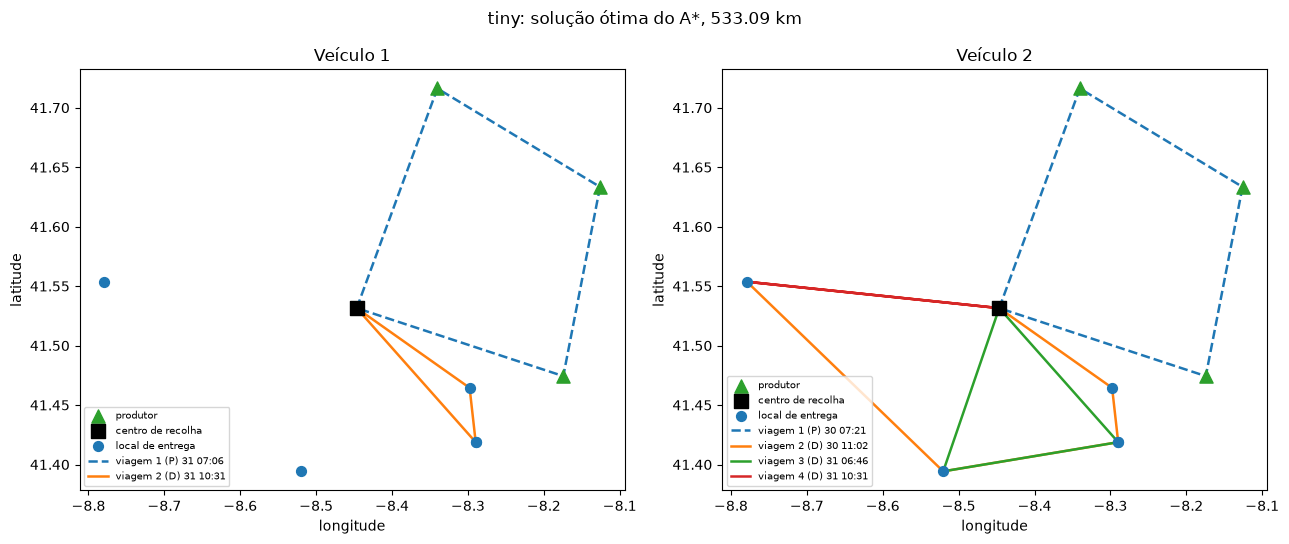

In [14]:
# rotas dos 2 veículos na solução ótima do tiny
best_tiny = optimal["tiny"].solution
tiny_eval = evaluate(tiny, best_tiny)
print(tiny_eval.summary())
print("verificador:", check_solution(tiny, tiny_eval).valid)
print_routes(best_tiny)
plot_routes(tiny, best_tiny, f"tiny: solução ótima do A*, {tiny_eval.km:.2f} km");

,vehicle,trip,stop,kind,arrival,start,window,weight
0,1,0,W,P,NaN,31 07:06,,NaN
1,1,0,P6,P,31 07:45,31 07:45,31 07:45-31 09:45,32.1
2,1,0,P4,P,31 08:29,31 08:29,31 08:15-31 10:00,29.9
3,1,0,P2,P,31 09:11,31 09:11,31 09:00-31 11:15,41.1
4,1,0,W,P,31 10:01,NaN,,NaN
5,1,1,W(carga),D,NaN,31 10:31,,NaN
6,1,1,D1,D,31 11:03,31 11:03,31 10:30-31 12:45,22.0
7,1,1,D6,D,31 11:13,31 11:13,31 10:45-31 13:15,16.7
8,1,1,D7,D,31 11:23,31 11:23,31 10:45-31 13:30,33.5
9,1,1,D5,D,31 11:42,31 11:42,31 10:30-31 12:30,9.3


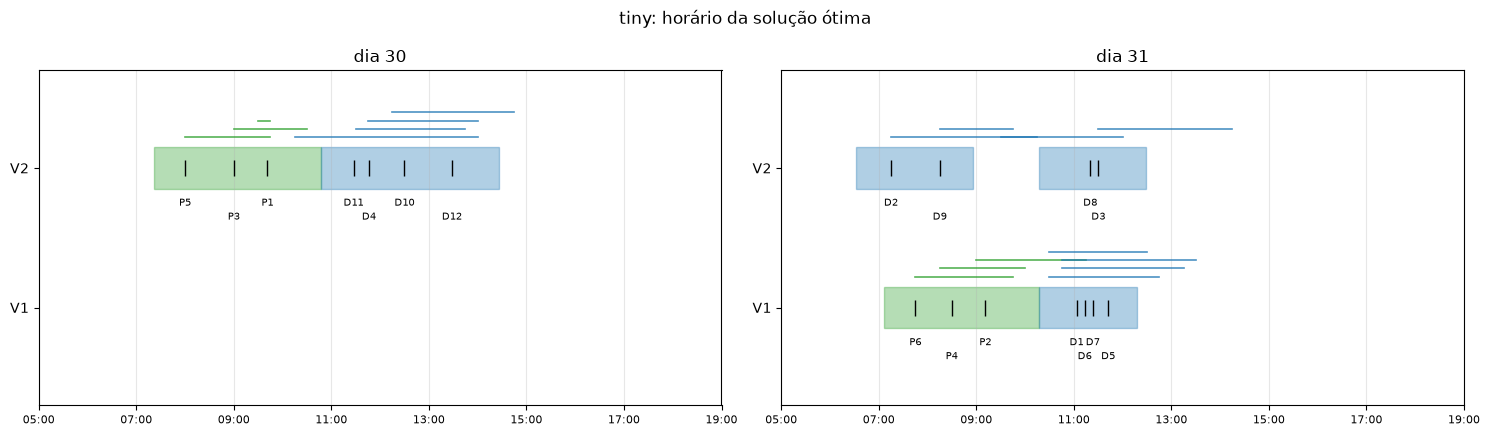

In [15]:
# horário da solução ótima, paragem a paragem
plot_gantt(tiny, tiny_eval, "tiny: horário da solução ótima");
schedule_table(tiny, tiny_eval)

Com h1 e h2, o A\* não encontra solução no tiny em 1 000 000 expansões; com h3 precisa de 709 786, e com h4 de 7 302. Por viagens e com h4, bastam 7 expansões no tiny e 19 no small. Como a h4 vale o custo da solução logo no estado inicial, os ótimos ficam provados: **533,09 km** no tiny e **757,84 km** no small. O Greedy com h3 ou h4 fica 15–17% acima.

## 5. Pesquisa local

Partimos da solução do Greedy com h3. Os movimentos são mudar um pedido de sítio, trocar dois pedidos e inverter um troço de uma viagem.

O Hill Climbing *steepest* passa sempre para o melhor vizinho. É simples e rápido, mas para no primeiro ótimo local. O *first improvement* passa para o primeiro vizinho que melhora, com passos mais baratos. O Simulated Annealing aceita às vezes pioras, com probabilidade exp(−Δ/T) cada vez menor, para conseguir sair de ótimos locais.

In [16]:
# HC e SA no tiny, a partir do Greedy com h3
start = greedy_results["h3_mst"].solution
hc_steepest = hill_climbing(tiny, start, "steepest")
hc_first = hill_climbing(tiny, start, "first", seed=0)
annealing = simulated_annealing(tiny, start, t0=30, alpha=0.9998, iters=30_000, seed=0)
pd.DataFrame([hc_steepest.summary(), hc_first.summary(), annealing.summary()])

,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,HC-steepest,625.46,533.09,14.77,True,5,2714,0.122
1,HC-first,625.46,533.09,14.77,True,5,705,0.044
2,SA,625.46,533.09,14.77,True,30000,30000,1.359


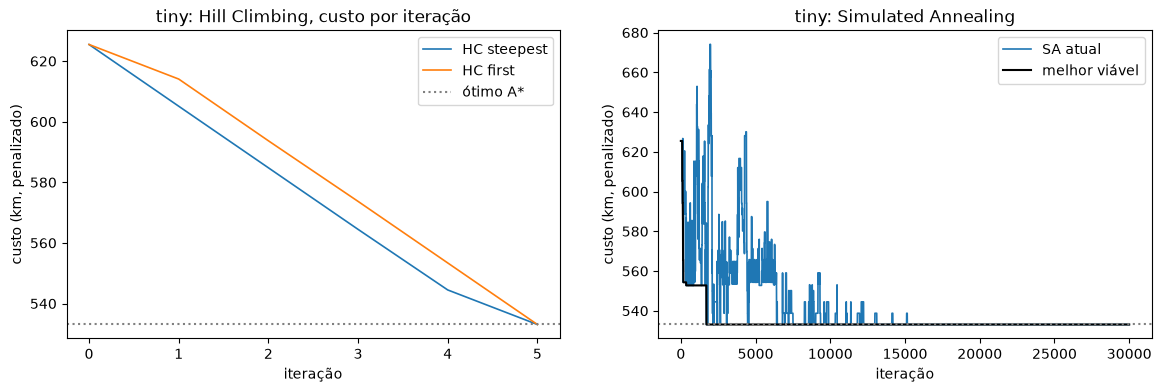

In [17]:
# custo por iteração no tiny
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({"HC steepest": dict(current=hc_steepest.history), "HC first": dict(current=hc_first.history)},
               "tiny: Hill Climbing, custo por iteração", ax=axes[0])
axes[0].axhline(tiny_eval.km, color="grey", ls=":", label="ótimo A*")
axes[0].legend()
plot_histories({"SA atual": dict(current=annealing.history)}, "tiny: Simulated Annealing", ax=axes[1], cap=800)
best_so_far = pd.Series(annealing.best_history).replace(float("inf"), None)
axes[1].plot(best_so_far.index, best_so_far.values, color="black", lw=1.5, label="melhor viável")
axes[1].axhline(tiny_eval.km, color="grey", ls=":")
axes[1].legend();

In [18]:
# movimentos aceites pelo HC steepest
print("movimentos aceites pelo HC steepest:")
for move in hc_steepest.moves:
    print("  ", move)

movimentos aceites pelo HC steepest:
   ('relocate', 'P6', 1, 0, 0)
   ('relocate', 'P2', 1, 0, 2)
   ('relocate', 'P1', 2, 0, 2)
   ('swap', 'D10', 'D11')
   ('relocate', 'D5', 1, 1, 0)


In [19]:
# HC steepest, 5 sementes de HC first e 5 de SA, nos dois datasets
runs = {}
for name, problem in PROBLEMS.items():
    initial = greedy(problem, h_mst).solution
    runs[name, "HC-steepest", 0] = hill_climbing(problem, initial, "steepest")
    for seed in range(5):
        runs[name, "HC-first", seed] = hill_climbing(problem, initial, "first", seed=seed)
        runs[name, "SA", seed] = simulated_annealing(problem, initial, t0=30, alpha=0.9998, iters=30_000, seed=seed)
local = pd.DataFrame([dict(dataset=name, seed=seed, **result.summary()) for (name, _, seed), result in runs.items()])
local.groupby(["dataset", "algorithm"]).agg(
    km_min=("final_km", "min"), km_media=("final_km", "mean"), km_max=("final_km", "max"),
    segundos=("seconds", "mean"), avaliacoes=("evaluated", "mean"), corridas=("seed", "count")).round(2)

km_min  km_media  km_max  segundos  avaliacoes  corridas
dataset algorithm                                                            
small   HC-first     799.35    817.06  834.22      0.53      4030.2         5
        HC-steepest  799.35    799.35  799.35      1.08     15904.0         1
        SA           771.69    801.54  821.94      2.22     30000.0         5
tiny    HC-first     533.09    533.09  533.09      0.05       821.8         5
        HC-steepest  533.09    533.09  533.09      0.12      2714.0         1
        SA           533.09    533.09  533.09      1.33     30000.0         5

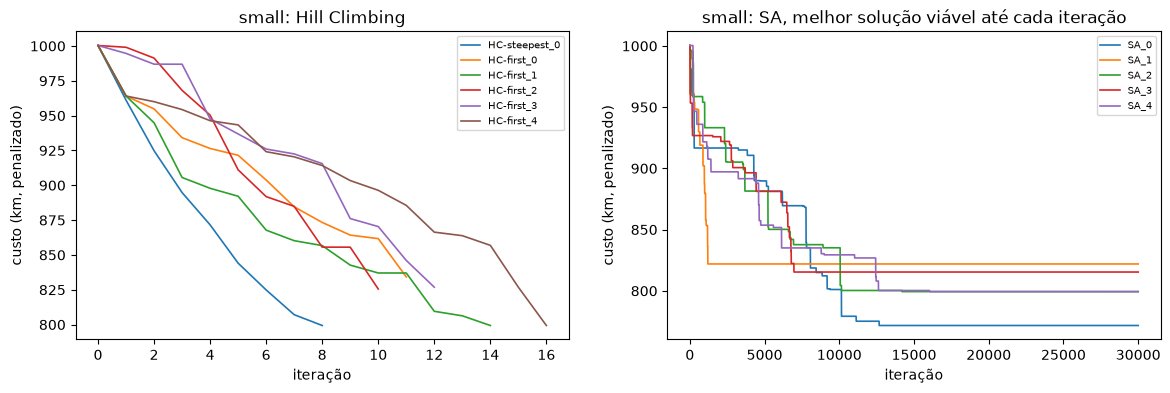

In [20]:
# custo por iteração no small
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_histories({f"{algorithm}_{seed}": dict(current=result.history) for (name, algorithm, seed), result in runs.items()
                if name == "small" and algorithm.startswith("HC")}, "small: Hill Climbing", ax=axes[0])
plot_histories({f"SA_{seed}": dict(current=[km if km != float("inf") else None for km in result.best_history])
                for (name, algorithm, seed), result in runs.items() if name == "small" and algorithm == "SA"},
               "small: SA, melhor solução viável até cada iteração", ax=axes[1]);

No tiny, os três chegam ao ótimo. No small, o HC *steepest* fica em 799,35 km, 5,5% acima do ótimo, e a melhor corrida do SA em 771,69 km, a 1,8%. Em média, porém, o SA não é melhor do que o HC.

## 6. CSP

Há uma variável por pedido. O domínio são triplos (veículo, dia, posição da viagem), com um modelo fixo de viagens por dia, `D-P-D-D-P-D-D`, e os pedidos com o mesmo valor formam uma viagem.

As restrições binárias garantem que dois pedidos na mesma viagem cabem no veículo e têm janelas compatíveis, que uma recolha vem antes da sua entrega no mesmo veículo e que a ordem das viagens respeita as janelas. A restrição global exige um horário viável, verificado com o simulador. A restrição suave é minimizar os km.

O backtracking atribui um pedido de cada vez e recua quando uma restrição falha. Com MRV, escolhe primeiro o pedido com menos opções, onde é mais provável falhar. Com a ordem *soft*, experimenta primeiro o valor que acrescenta menos km, para a primeira solução já ser barata.

O forward checking tira aos outros pedidos os valores que deixaram de ser possíveis, para detetar becos sem saída mais cedo. O MAC propaga essas remoções em cadeia com o AC-3, à custa de mais trabalho por nó, e o FC global faz o mesmo contra o horário completo. Depois da primeira solução, o branch & bound continua a procurar só soluções mais baratas.

In [21]:
# dimensão do CSP do tiny e domínio de um pedido
tiny_csp = RoutingCSP(tiny)
print("variáveis:", len(tiny_csp.vars), "| valores iniciais:", sum(map(len, tiny_csp.domains.values())),
      "| pares com restrição binária:", sum(map(len, tiny_csp.neigh.values())) // 2)
print("domínio de D2:", tiny_csp.domains["D2"])

variáveis: 18 | valores iniciais: 144 | pares com restrição binária: 149
domínio de D2: [(1, 1, 0), (1, 1, 2), (1, 1, 3), (1, 1, 5), (1, 1, 6), (2, 1, 0), (2, 1, 2), (2, 1, 3), (2, 1, 5), (2, 1, 6)]


In [22]:
# primeira solução do tiny com cada tipo de inferência
rows = []
for inference in ("none", "fc", "mac"):
    for global_fc in (False, True):
        rows.append(solve(tiny, inference=inference, global_fc=global_fc).summary())
pd.DataFrame(rows)

,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds
0,none,mrv,soft,False,False,viável,659.27,25,7,26,0,1,0.013
1,none,mrv,soft,True,False,viável,621.57,18,0,1258,60,1,0.051
2,fc,mrv,soft,False,False,viável,659.27,21,3,22,37,1,0.004
3,fc,mrv,soft,True,False,viável,621.57,18,0,1206,60,1,0.049
4,mac,mrv,soft,False,False,viável,659.27,21,3,22,37,1,0.011
5,mac,mrv,soft,True,False,viável,621.57,18,0,1201,60,1,0.053


In [23]:
# backtracks de cada configuração, com 20 000 atribuições por corrida
rows = []
for name, problem in PROBLEMS.items():
    for inference in ("none", "fc", "mac"):
        for var_order in ("static", "mrv"):
            for value_order in ("static", "soft"):
                for global_fc in (False, True):
                    result = solve(problem, inference=inference, var_order=var_order, value_order=value_order,
                                   global_fc=global_fc, max_assignments=20_000, time_limit=90)
                    rows.append(dict(dataset=name, **result.summary()))
    result = solve(problem, global_fc=True, optimize=True, max_assignments=20_000, time_limit=600)
    rows.append(dict(dataset=name, **result.summary()))
csp_results = pd.DataFrame(rows)
first_solutions = csp_results[~csp_results.optimize]
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="backtracks", aggfunc="first")

dataset                          small        tiny      
global_fc                        False True  False True 
inference var_order value_order                         
fc        mrv       soft             1     1     3     0
                    static           5     0     3     0
          static    soft             6     3     7     0
                    static           4     0     3     0
mac       mrv       soft             0     0     3     0
                    static           5     0     3     0
          static    soft             5     2     7     0
                    static           4     0     3     0
none      mrv       soft             5     1     7     0
                    static           4     0     3     0
          static    soft         19975     3     7     0
                    static           4     0     3     0

In [24]:
# km da primeira solução de cada configuração
first_solutions.pivot_table(index=["inference", "var_order", "value_order"], columns=["dataset", "global_fc"],
                            values="cost_km", aggfunc="first")

dataset                           small            tiny        
global_fc                         False   True    False   True 
inference var_order value_order                                
fc        mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
mac       mrv       soft         806.18  841.05  659.27  621.57
                    static       865.24  865.24  659.27  659.27
          static    soft         895.42  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27
none      mrv       soft         895.42  841.05  659.27  621.57
                    static       819.13  865.24  659.27  659.27
          static    soft            NaN  930.29  659.27  659.27
                    static       819.13  819.13  659.27  659.27

In [25]:
# branch & bound nos dois datasets
csp_results[csp_results.optimize]

,dataset,inference,var_order,value_order,global_fc,optimize,status,cost_km,assignments,backtracks,checks,pruned,solutions,seconds
24,tiny,mac,mrv,soft,True,True,melhor encontrada (limite),621.57,20000,19985,435282,4365,1,32.810
49,small,mac,mrv,soft,True,True,melhor encontrada (limite),792.71,20000,19976,412028,8627,4,57.685


No small, sem inferência e com ordem estática, o backtracking não encontra solução em 20 000 atribuições; com forward checking ou MAC e MRV bastam 0–1 backtracks. O branch & bound chega a 792,71 km no small, cerca de 4,6% acima do ótimo, sem provar que é ótimo.

## 7. Análise de resultados

In [26]:
# comparação: melhor km, tempo e esforço de cada método
rows = []
for dataset in ("tiny", "small"):
    for algorithm in ("Greedy", "A*", "A*-viagens"):
        for heuristic in ("h1_max_detour", "h2_min_arcs", "h3_mst", "h4_relaxed"):
            match = informed[(informed.dataset == dataset) & (informed.algorithm == algorithm)
                             & (informed.heuristic_name == heuristic)]
            if len(match):
                run = match.iloc[0]
                rows.append(dict(dataset=dataset, metodo=f"{algorithm} {heuristic.split('_')[0]}", km=run.cost_km,
                                 segundos=run.seconds, esforco=f"{int(run.expanded)} expansões",
                                 completo=run.complete))
    for algorithm in ("HC-steepest", "HC-first", "SA"):
        runs = local[(local.dataset == dataset) & (local.algorithm == algorithm)]
        rows.append(dict(dataset=dataset, metodo=f"{algorithm} (melhor de {len(runs)})", km=runs.final_km.min(),
                         segundos=runs.seconds.mean(), esforco=f"{int(runs.evaluated.mean())} avaliações",
                         completo=None))
    mrv_soft = (csp_results.var_order == "mrv") & (csp_results.value_order == "soft") & ~csp_results.optimize
    csp_configs = [
        ("CSP FC+MRV+soft", mrv_soft & (csp_results.inference == "fc") & ~csp_results.global_fc),
        ("CSP MAC+MRV+soft", mrv_soft & (csp_results.inference == "mac") & ~csp_results.global_fc),
        ("CSP MAC+MRV+soft+FC global", mrv_soft & (csp_results.inference == "mac") & csp_results.global_fc),
        ("CSP branch & bound", csp_results.optimize),
    ]
    for label, mask in csp_configs:
        run = csp_results[(csp_results.dataset == dataset) & mask].iloc[0]
        rows.append(dict(dataset=dataset, metodo=label, km=run.cost_km, segundos=run.seconds,
                         esforco=f"{int(run.backtracks)} backtracks", completo=None))
comparison = pd.DataFrame(rows)
comparison.round(2)

,dataset,metodo,km,segundos,esforco,completo
0,tiny,Greedy h1,707.16,0.01,46 expansões,True
1,tiny,Greedy h2,674.14,0.00,29 expansões,True
2,tiny,Greedy h3,625.46,0.00,29 expansões,True
3,tiny,Greedy h4,611.13,0.00,28 expansões,True
4,tiny,A* h1,NaN,227.17,1000000 expansões,False
5,tiny,A* h2,NaN,255.77,1000000 expansões,False
6,tiny,A* h3,533.09,176.76,709786 expansões,True
7,tiny,A* h4,533.09,1.01,7302 expansões,True
8,tiny,A*-viagens h3,533.09,5.48,3681 expansões,True
9,tiny,A*-viagens h4,533.09,0.01,7 expansões,True


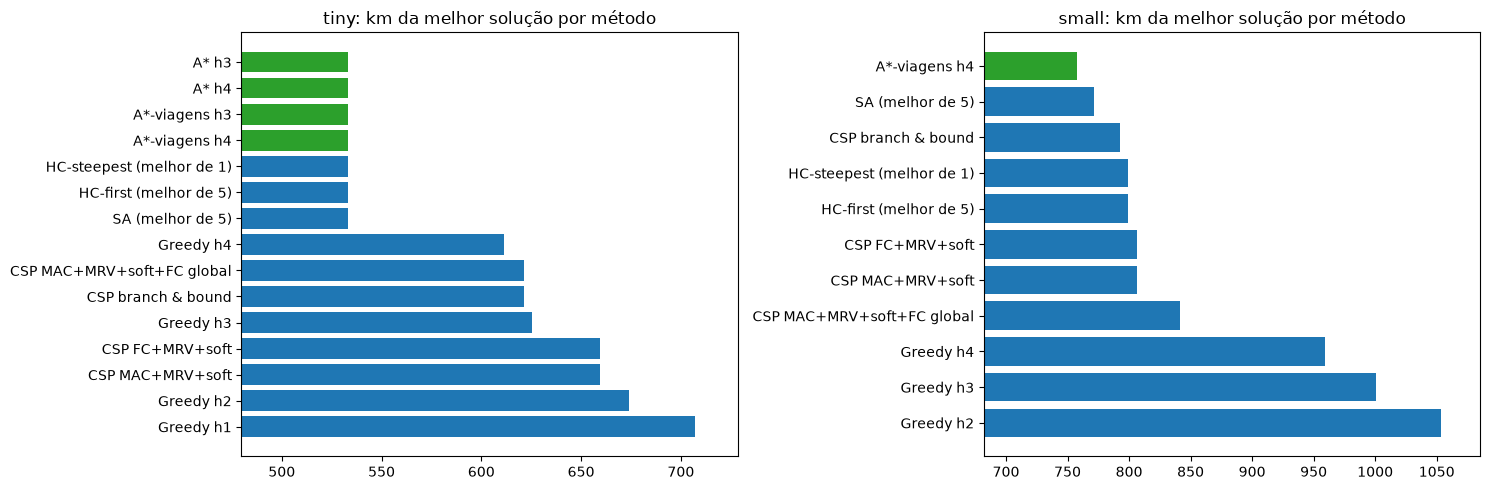

In [27]:
# km da melhor solução de cada método
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, dataset in zip(axes, ("tiny", "small")):
    methods = comparison[(comparison.dataset == dataset) & comparison.km.notna()].sort_values("km")
    ax.barh(methods.metodo, methods.km,
            color=["tab:green" if method.startswith("A*") else "tab:blue" for method in methods.metodo])
    ax.set_xlim(methods.km.min() * 0.9, methods.km.max() * 1.03)
    ax.set_title(f"{dataset}: km da melhor solução por método")
    ax.invert_yaxis()
fig.tight_layout()

### 7.1 Melhor solução do small

{'km': 757.84, 'feasible': True, 'trips': 6, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2515.7, 'route_min': 1466.7}
verificador: True
Veículo 1: W→P9→W | W→D15→D16→D6→D18→D19→D1→D9→D2→W | W→D23→D5→D25→D14→D11→D17→W
Veículo 2: W→P7→P11→P1→P3→P5→W | W→P8→P12→P2→P4→P6→P10→W | W→D7→D21→D24→D10→D22→D13→D8→D12→D3→D20→D4→W


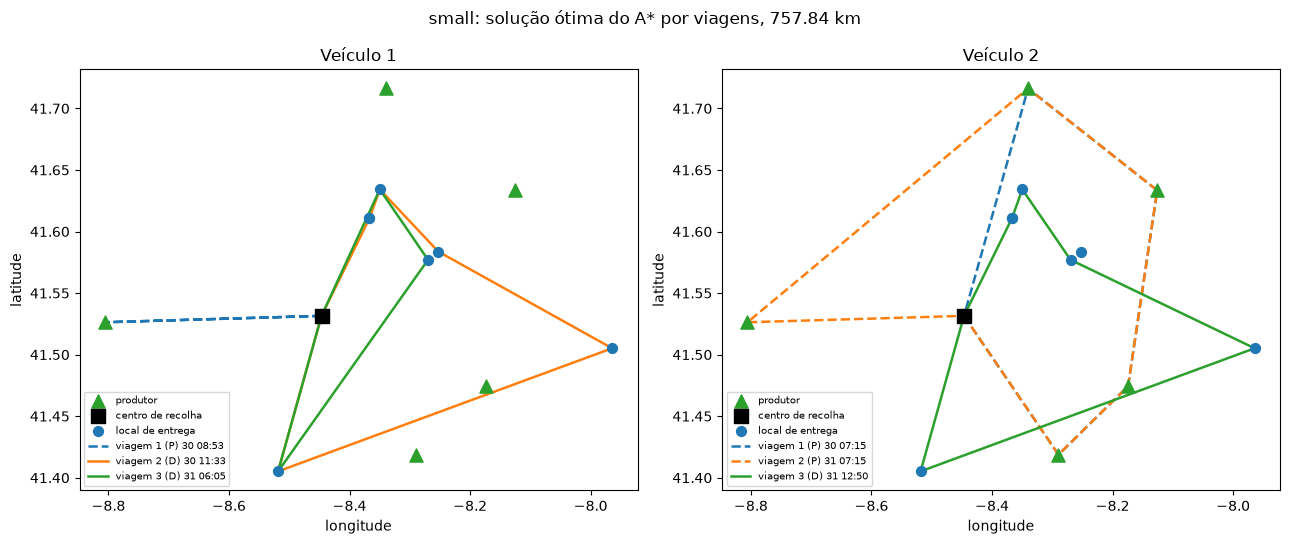

In [28]:
# solução ótima do small
best_small = optimal["small"].solution
small_eval = evaluate(small, best_small)
print(small_eval.summary())
print("verificador:", check_solution(small, small_eval).valid)
print_routes(best_small)
plot_routes(small, best_small, f"small: solução ótima do A* por viagens, {small_eval.km:.2f} km");

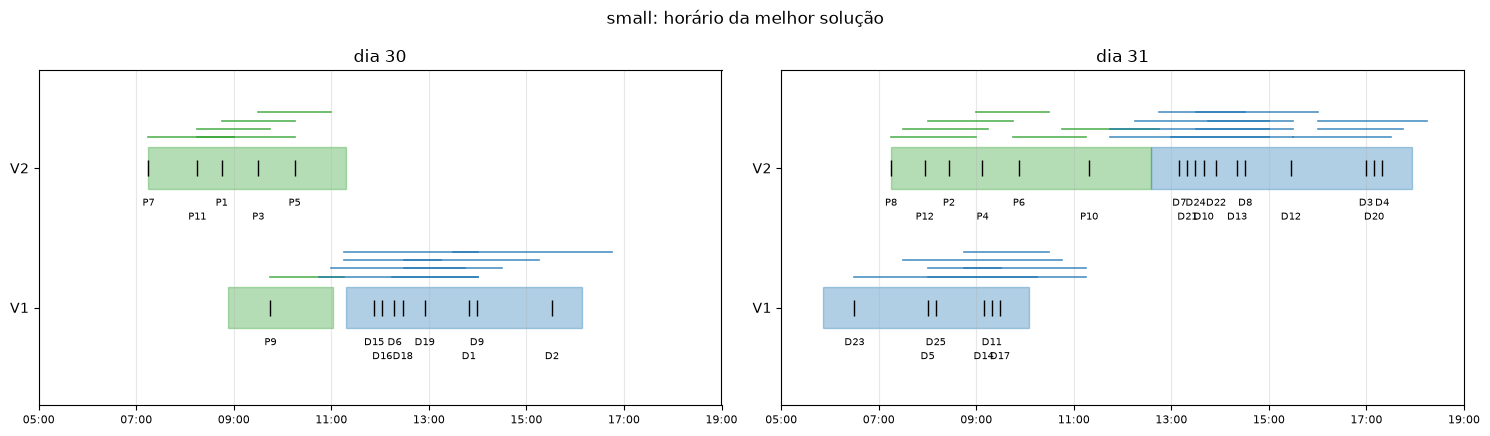

In [29]:
# horário da solução ótima do small
plot_gantt(small, small_eval, "small: horário da melhor solução");

### 7.2 Análise crítica

O A\* por viagens com h4 prova o ótimo nos dois datasets. A pesquisa local fica a 0–10% do ótimo e o CSP a 5–24%.

O A\* exato só escala com uma boa heurística e ações ao nível da viagem. A pesquisa local é rápida e escalaria melhor, mas não dá garantias. O CSP encontra depressa uma solução viável, mas os km só entram pela ordenação dos valores e pelo branch & bound.

Como melhorias, ficam as viagens mistas, com recolhas e entregas na mesma volta, as recolhas parciais, uma vizinhança maior na pesquisa local e CP-SAT para instâncias maiores.

Tempos de uma execução num portátil:

| Método | tiny | small |
|---|---|---|
| Greedy | milissegundos | 0,2–0,6 s, ou 21 s sem solução com h1 |
| A\* paragem a paragem | 1,7 s com h4, 3–4 min com as outras | não termina |
| A\* por viagens com h4 | centésimas de segundo | 3,5 s, mais 19 s para construir o catálogo |
| Hill Climbing | décimas de segundo | cerca de 1 s |
| SA com 30 000 iterações | 1–2,5 s | cerca de 2,5 s |
| CSP com FC ou MAC | centésimas de segundo | centésimas de segundo, 0,3 s com FC global |
| CSP com branch & bound | 35 s, esgota o orçamento | 54 s, esgota o orçamento |

## 8. Conclusão

Provámos o ótimo dos dois datasets, 533,09 km no tiny e 757,84 km no small, com todas as soluções confirmadas pelo verificador. O que mais pesou foi a formulação: com ações ao nível da viagem e uma heurística forte, o A\* passa de não terminar a resolver o small em segundos. A maior dificuldade foi a dependência entre veículos através do armazém. O código está nos módulos `model`, `informed`, `local_search` e `csp`, com testes unitários, e usámos Python, pandas, matplotlib e Jupyter.